In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


base_dir = Path.cwd()
data_folder = base_dir / 'data' / 'Strava-export_47979926'

In [2]:
csv_files = list(data_folder.glob('*.csv'))
print(f"Found {len(csv_files)} CSV files.")



Found 35 CSV files.


In [3]:
file_name = 'activities.csv'  
file_path = data_folder / file_name

if file_path.exists():
    df = pd.read_csv(file_path)
    print("Data loaded successfully!")
    print(df.head())
else:
    print(f"File not found: {file_path}")

print("\nDataFrame Info:")
print(df.info())

print("\nSummary Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Data loaded successfully!
   Aktivitäts-ID       Aktivitätsdatum       Name der Aktivität Aktivitätsart  \
0     2839978533  04.09.2019, 15:39:30  Schwimmen am Nachmittag     Schwimmen   
1     2839978543  28.08.2019, 08:57:32      Schwimmen am Morgen     Schwimmen   
2     2839978546  03.09.2019, 05:59:57      Aktivität am Morgen      Training   
3     2839978551  18.08.2019, 17:38:05            Abendradfahrt      Radfahrt   
4     2839978553  07.09.2019, 13:18:20  Wanderung am Nachmittag       Wandern   

  Aktivitätsbeschreibung  Verstrichene Zeit Distanz  Max. Herzfrequenz  \
0                    NaN               2482   1.041                NaN   
1                    NaN                791     531                NaN   
2                    NaN                528    0,06                NaN   
3                    NaN               2011   10,29                NaN   
4                    NaN               3578    9,16                NaN   

   Relative Leistung  Pendeln  ...  Aktivi

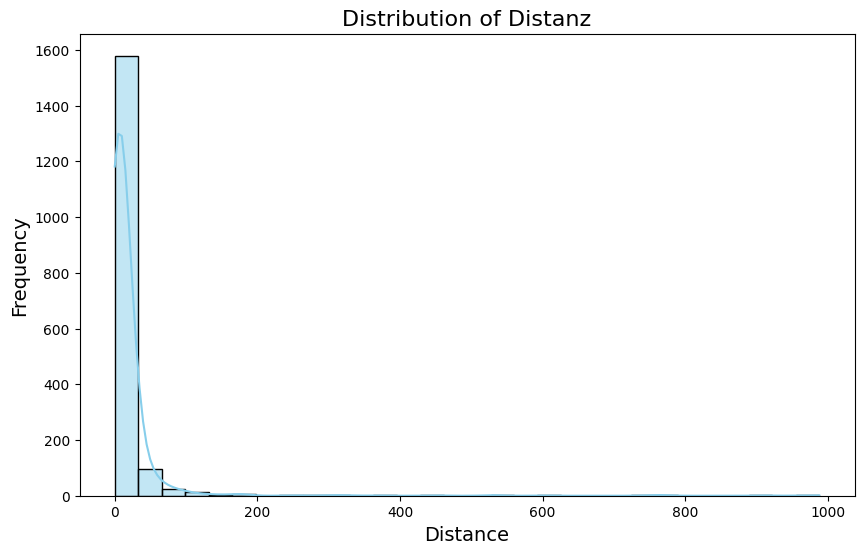

In [4]:


column = 'Distanz'

if column in df.columns:

    df[column] = df[column].str.replace(',', '.', regex=False)
    df[column] = pd.to_numeric(df[column], errors='coerce')  

    # Drop NaN values for plotting
    distanz_clean = df[column].dropna()

    
    plt.figure(figsize=(10, 6))
    sns.histplot(distanz_clean, bins=30, kde=True, color='skyblue')
    plt.title('Distribution of Distanz', fontsize=16)
    plt.xlabel('Distance', fontsize=14) 
    plt.ylabel('Frequency', fontsize=14)
    plt.show()
else:
    print(f"Column {column} not found in the DataFrame.")


In [5]:

missing_percentage = df.isnull().mean() * 100


high_missing = missing_percentage[missing_percentage > 50]
print("Columns with more than 50% missing values:")
print(high_missing.sort_values(ascending=False))

Columns with more than 50% missing values:
Neu getestete Schotterdistanz               100.000000
Bergaufzeit                                 100.000000
Ausrüstung                                  100.000000
Hinweis zur Privatsphäre für Aktivitäten    100.000000
Wetter: Ozon                                100.000000
                                               ...    
Durchschnittliche Watt                       82.064591
Medien                                       78.835063
Max. Herzfrequenz.1                          77.797001
Gefühlte Anstrengung verwenden               76.412918
Auf Steigung angepasste Distanz              72.779700
Length: 62, dtype: float64


In [6]:
threshold = 80
cols_to_drop = missing_percentage[missing_percentage > threshold].index
print(f"\nDropping {len(cols_to_drop)} columns with more than {threshold}% missing values.")



Dropping 58 columns with more than 80% missing values.


In [7]:
df_cleaned = df.drop(columns=cols_to_drop)

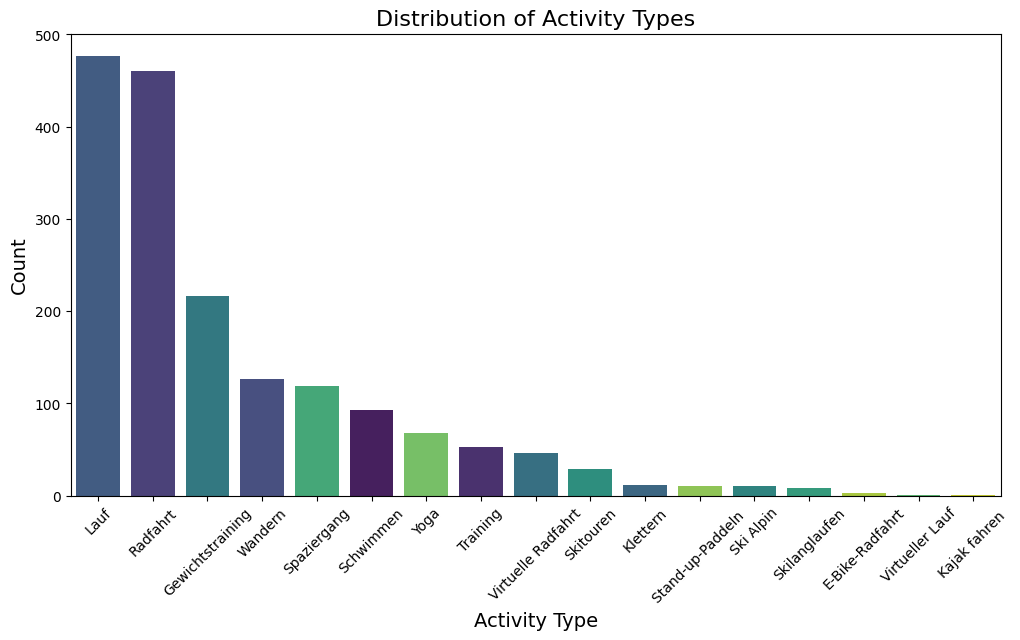

In [13]:
import matplotlib.pyplot as plt

# Assign `x` variable to `hue` and set `legend=False`
plt.figure(figsize=(12, 6))
sns.countplot(data=df_cleaned, x='Aktivitätsart', order=df_cleaned['Aktivitätsart'].value_counts().index, hue='Aktivitätsart', palette='viridis', dodge=False, legend=False)
plt.title('Distribution of Activity Types', fontsize=16)
plt.xlabel('Activity Type', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(rotation=45)
plt.show()



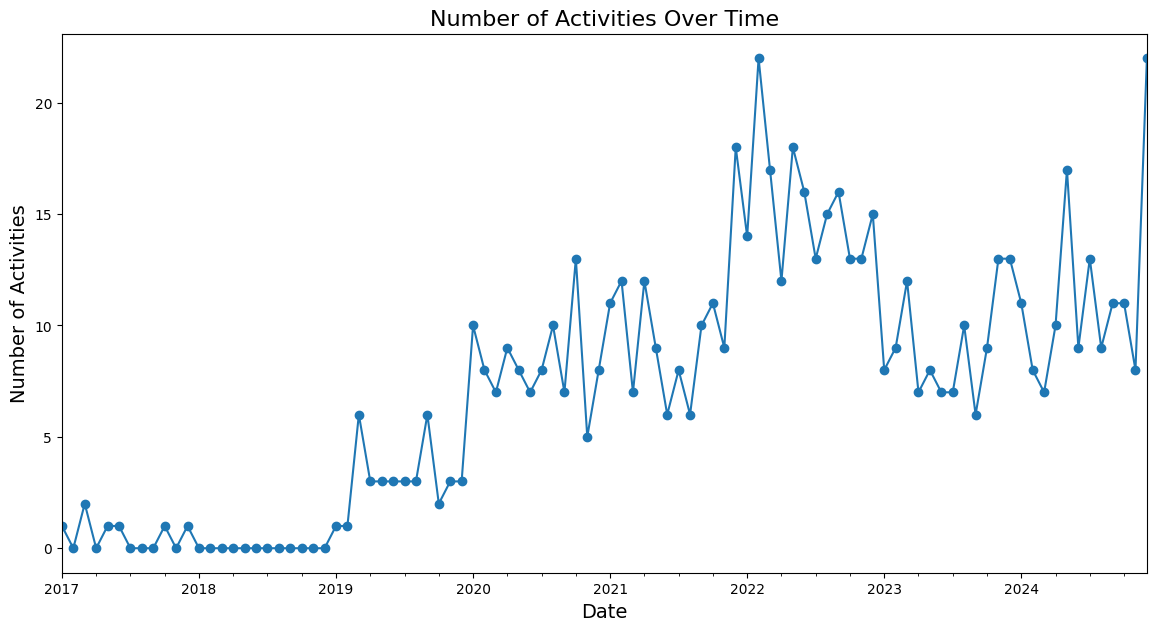

In [14]:

df_cleaned['Aktivitätsdatum'] = pd.to_datetime(df_cleaned['Aktivitätsdatum'], errors='coerce')


df_time = df_cleaned.dropna(subset=['Aktivitätsdatum'])


df_time.set_index('Aktivitätsdatum', inplace=True)


monthly_activities = df_time.resample('ME').size()

# Plot the time series
plt.figure(figsize=(14, 7))
monthly_activities.plot(marker='o', linestyle='-')
plt.title('Number of Activities Over Time', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Number of Activities', fontsize=14)
plt.show()


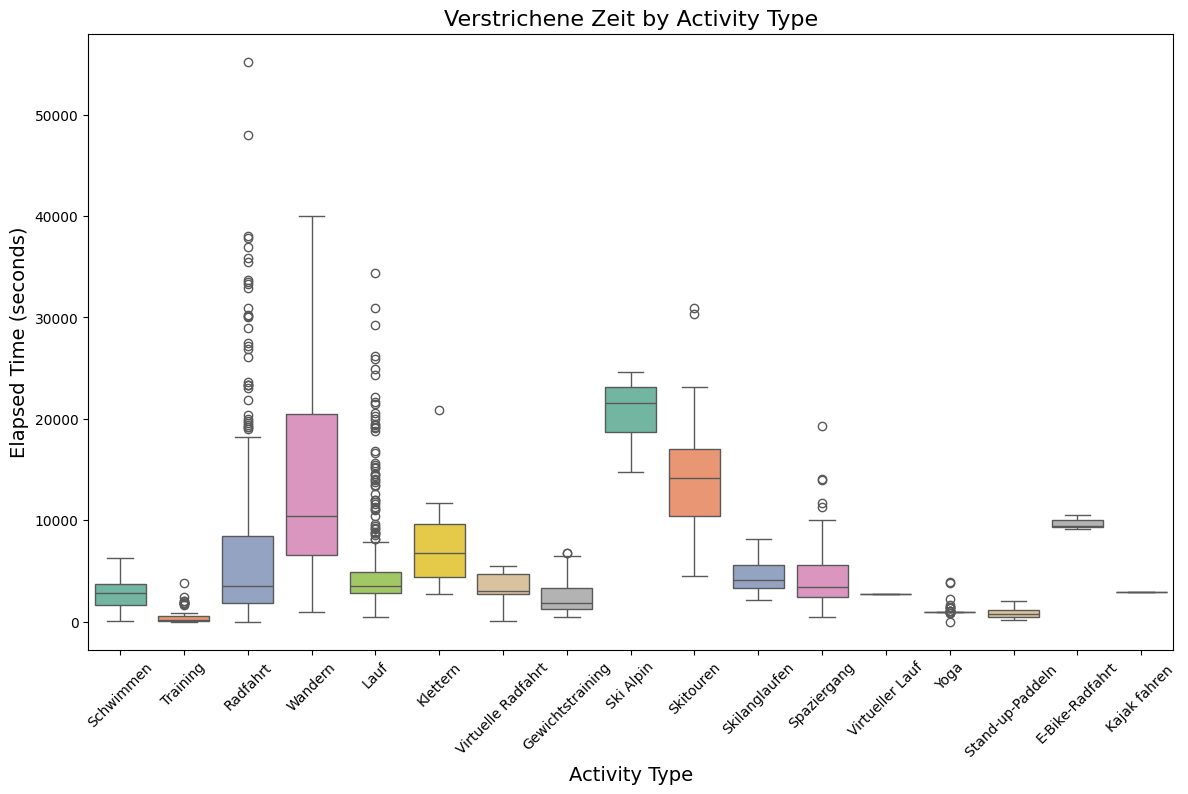

In [15]:
plt.figure(figsize=(14, 8))
sns.boxplot(data=df_cleaned, x='Aktivitätsart', y='Verstrichene Zeit',hue='Aktivitätsart', palette='Set2')
plt.title('Verstrichene Zeit by Activity Type', fontsize=16)
plt.xlabel('Activity Type', fontsize=14)
plt.ylabel('Elapsed Time (seconds)', fontsize=14)
plt.xticks(rotation=45)
plt.show()
